In [ ]:
# Dog Breed Classification using Transfer Learning

**Problem Statement:** Develop an image classifier to identify dog breeds using pretrained CNN architectures.

**Activities:**
1. Setup and Data Loading
2. Fine-tuning a pretrained model (MobileNetV2)
3. Evaluation of classification accuracy

In [ ]:
import os
import sys

# Attempt to fix the protobuf issue by ensuring a compatible version is present
!pip install "protobuf>=3.20.3,<5.0.0" --quiet

# Clear the internal cache to force re-import of the fixed library
if 'tensorflow_datasets' in sys.modules:
    del sys.modules['tensorflow_datasets']

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
try:
    import tensorflow_datasets as tfds
    print("TensorFlow Datasets imported successfully.")
except Exception as e:
    print(f"Import failed: {e}. Please restart the runtime and try again.")

from tensorflow.keras import layers, models

ERROR:absl:Detected incompatible Protobuf Gencode/Runtime versions when loading tensorflow_metadata/proto/v0/schema.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/__init__.py", line 79, in <module>
    from tensorflow_datasets import rlds  # pylint: disable=g-bad-import-order
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/rlds/__init__.py", line 22, in <module>
    from tensorflow_datasets.rlds import rlds_base
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/rlds/rlds_base.py", line 26, in <module>
    import tensorflow_datasets.public_api as tfds
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/public_api.py", line 21, in <module>
   

TensorFlow Datasets imported successfully.


In [ ]:
import os
import tarfile
import tensorflow as tf

# Download and robustly extract the dataset
dataset_url = "http://vision.stanford.edu/aditya86/ImageNetDogs/images.tar"
tar_path = tf.keras.utils.get_file('images.tar', origin=dataset_url)

extract_path = os.path.join(os.path.dirname(tar_path), 'stanford_dogs_extracted')
if not os.path.exists(extract_path):
    os.makedirs(extract_path)
    print("Extracting dataset...")
    with tarfile.open(tar_path, 'r') as tar:
        tar.extractall(path=extract_path)

# The tar contains an 'Images' folder
data_dir = os.path.join(extract_path, 'Images')

IMG_SIZE = 224
BATCH_SIZE = 32

# Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

num_classes = len(train_ds.class_names)
print(f'Successfully loaded {num_classes} classes.')

Extracting dataset...


/tmp/ipykernel_891/33890249.py:14: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Found 20580 files belonging to 120 classes.
Using 16464 files for training.
Found 20580 files belonging to 120 classes.
Using 4116 files for validation.
Successfully loaded 120 classes.


In [ ]:
# Preprocessing pipeline for MobileNetV2
def preprocess(image, label):
    # MobileNetV2 expects inputs in [-1, 1]
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

In [ ]:
# Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze the base model
base_model.trainable = False

# Add custom head
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │       153,720 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,411,704 (9.20 MB)

 Trainable params: 153,720 (600.47 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Initial training (Transfer Learning)
history = model.fit(
    train_ds,
    epochs=5,
    validation_data=test_ds
)

Epoch 1/5
515/515 ━━━━━━━━━━━━━━━━━━━━ 533s 1s/step - accuracy: 0.7062 - loss: 1.1560 - val_accuracy: 0.8175 - val_loss: 0.5910
Epoch 2/5
515/515 ━━━━━━━━━━━━━━━━━━━━ 533s 1s/step - accuracy: 0.8669 - loss: 0.4322 - val_accuracy: 0.8331 - val_loss: 0.5341
Epoch 3/5
515/515 ━━━━━━━━━━━━━━━━━━━━ 541s 1s/step - accuracy: 0.9067 - loss: 0.3036 - val_accuracy: 0.8309 - val_loss: 0.5269
Epoch 4/5
515/515 ━━━━━━━━━━━━━━━━━━━━ 521s 970ms/step - accuracy: 0.9347 - loss: 0.2268 - val_accuracy: 0.8253 - val_loss: 0.5412
Epoch 5/5
515/515 ━━━━━━━━━━━━━━━━━━━━ 543s 1s/step - accuracy: 0.9504 - loss: 0.1786 - val_accuracy: 0.8314 - val_loss: 0.5294


129/129 ━━━━━━━━━━━━━━━━━━━━ 108s 835ms/step - accuracy: 0.8314 - loss: 0.5294
Test Accuracy: 83.14%


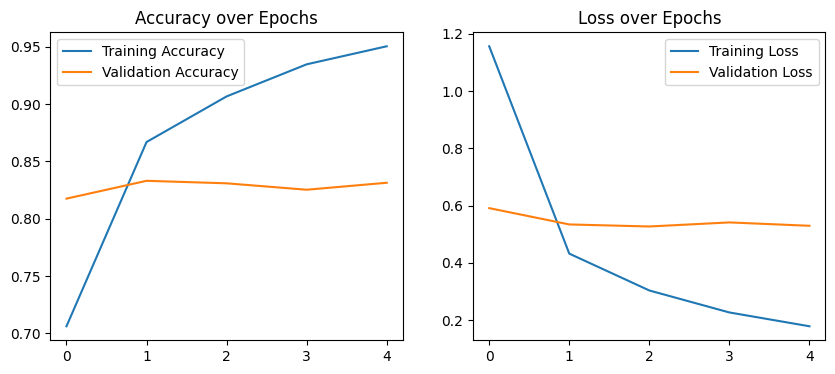

In [ ]:
# Evaluate classification accuracy on the test set
test_loss, test_accuracy = model.evaluate(test_ds)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Plot training results
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy over Epochs')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Loss over Epochs')
plt.show()